# ASSISTments 2015 — Dataset 2: Four-Model Evaluation

**Models:** Bayesian Knowledge Tracing (BKT), Logistic Regression, Decision Tree, and Random Forest.

This notebook loads the supplied ASSISTments 2015 CSV, prepares a consistent binary-response dataset, trains and evaluates all four models, and saves the results. Each student belongs to only one split. The chronological `log_id` is used to order interactions.

## 1. Import libraries

Load the libraries used for data preparation, modelling, evaluation, and plots.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, confusion_matrix, classification_report
from IPython.display import display

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the supplied dataset

Update `file_path` only if the CSV is stored in a different folder.

In [2]:
file_path = "2015_100_skill_builders_main_problems (1).csv"
data = pd.read_csv(file_path, encoding="cp1252", low_memory=False)
print("Original shape:", data.shape)
display(data.head())

Original shape: (708631, 4)


,user_id,log_id,sequence_id,correct
0,50121,167478035,7014,0.0
1,50121,167478043,7014,1.0
2,50121,167478053,7014,1.0
3,50121,167478069,7014,1.0
4,50964,167478041,7014,1.0


## 3. Inspect the data

The supplied file has four columns: student ID, interaction ID, sequence ID, and correctness score. Check the values before preparing the modelling target.

In [3]:
print(data.info())
print("\nMissing values:")
display(data.isna().sum().to_frame("Missing values"))
print("Unique students:", data["user_id"].nunique())
print("Unique interactions:", data["log_id"].nunique())
print("Unique sequences:", data["sequence_id"].nunique())
print("\nCorrectness scores:")
display(data["correct"].value_counts(dropna=False).sort_index().to_frame("Count"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708631 entries, 0 to 708630
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      708631 non-null  int64  
 1   log_id       708631 non-null  int64  
 2   sequence_id  708631 non-null  int64  
 3   correct      708631 non-null  float64
dtypes: float64(1), int64(3)
memory usage: 21.6 MB
None

Missing values:


,Missing values
user_id,0
log_id,0
sequence_id,0
correct,0


Unique students: 19917
Unique interactions: 708631
Unique sequences: 100

Correctness scores:


,Count
correct,
0.000000,183422
0.100000,1
0.200000,2
0.250000,75
0.333333,8383
0.500000,101
0.666667,15981
0.750000,282
0.800000,2


## 4. Prepare a consistent binary target

The `correct` field contains full-credit values (0 and 1) and partial-credit values between them. BKT requires binary responses, so this experiment keeps only rows with an exact score of 0 or 1. Partial-credit rows are excluded rather than converted using an arbitrary threshold.

In [4]:
data = data.drop_duplicates().copy()
data = data.dropna(subset=["user_id", "log_id", "sequence_id", "correct"]).copy()
data["correct"] = pd.to_numeric(data["correct"], errors="coerce")
data = data.dropna(subset=["correct"])

original_rows = len(data)
partial_credit_rows = (~data["correct"].isin([0.0, 1.0])).sum()
data = data[data["correct"].isin([0.0, 1.0])].copy()
data["target"] = data["correct"].astype(int)
data["user_id"] = data["user_id"].astype(int)
data["log_id"] = data["log_id"].astype(int)
data["sequence_id"] = data["sequence_id"].astype(int)
data = data.sort_values(["user_id", "sequence_id", "log_id"]).reset_index(drop=True)

print("Rows retained:", len(data))
print("Partial-credit rows excluded:", partial_credit_rows)
print("Students retained:", data["user_id"].nunique())
print("Sequences retained:", data["sequence_id"].nunique())
print("Binary correctness rate:", round(data["target"].mean(), 4))
display(data.head())

Rows retained: 683801
Partial-credit rows excluded: 24830
Students retained: 19840
Sequences retained: 100
Binary correctness rate: 0.7318


,user_id,log_id,sequence_id,correct,target
0,50121,167478035,7014,0.0,0
1,50121,167478043,7014,1.0,1
2,50121,167478053,7014,1.0,1
3,50121,167478069,7014,1.0,1
4,50964,167478041,7014,1.0,1


## 5. Exploratory data analysis

Review the correct/incorrect balance and the distribution of interactions per student and per sequence.

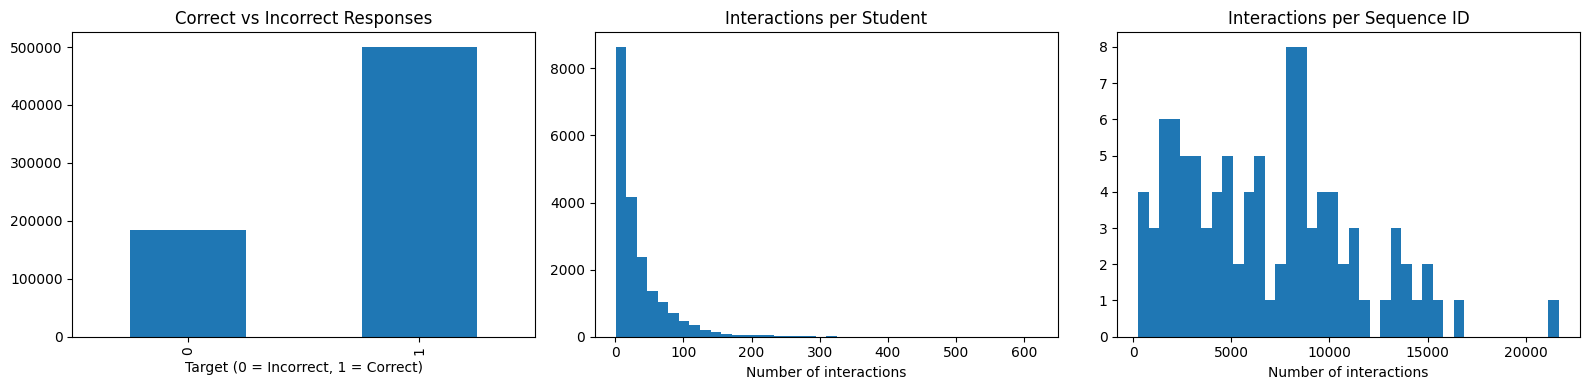

Median interactions per student: 20.0
Mean interactions per student: 34.47


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
data["target"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Correct vs Incorrect Responses")
axes[0].set_xlabel("Target (0 = Incorrect, 1 = Correct)")
student_counts = data.groupby("user_id").size()
axes[1].hist(student_counts, bins=40)
axes[1].set_title("Interactions per Student")
axes[1].set_xlabel("Number of interactions")
sequence_counts = data.groupby("sequence_id").size()
axes[2].hist(sequence_counts, bins=40)
axes[2].set_title("Interactions per Sequence ID")
axes[2].set_xlabel("Number of interactions")
plt.tight_layout()
plt.show()
print("Median interactions per student:", student_counts.median())
print("Mean interactions per student:", round(student_counts.mean(), 2))

## 6. Split by student

Use an 80/20 student-level split. This prevents interactions from the same student appearing in both training and testing data.

For computational efficiency, the three conventional classifiers are trained on a reproducible stratified sample of 180,000 training interactions. The complete held-out test set is retained. BKT parameters are fitted using a reproducible sample of 2,500 sequences from the full training split. These training-sample differences are disclosed because they matter when interpreting model comparisons.

In [6]:
student_ids = data["user_id"].drop_duplicates().to_numpy()
train_users, test_users = train_test_split(
    student_ids, test_size=0.20, random_state=RANDOM_STATE
)
train_data = data[data["user_id"].isin(train_users)].copy()
test_data = data[data["user_id"].isin(test_users)].copy()
print("Training rows:", len(train_data), "| Training students:", train_data["user_id"].nunique())
print("Testing rows:", len(test_data), "| Testing students:", test_data["user_id"].nunique())
print("Student overlap:", len(set(train_users).intersection(set(test_users))))

train_full_data = train_data.copy()
train_data = train_data.groupby("target", group_keys=False).apply(
    lambda group: group.sample(n=min(len(group), 90000), random_state=RANDOM_STATE)
).sample(frac=1, random_state=RANDOM_STATE).sort_values(["user_id", "sequence_id", "log_id"]).copy()
print("Training rows used for modelling after stratified sampling:", len(train_data))

Training rows: 551093 | Training students: 15872
Testing rows: 132708 | Testing students: 3968
Student overlap: 0
Training rows used for modelling after stratified sampling: 180000


## 7. Build chronological history features

For each student and sequence, calculate the number of earlier responses and the earlier correctness rate. The current response is shifted out, so it cannot contribute to its own features. For test students, earlier test interactions represent history available at prediction time.

In [7]:
def add_history_features(frame):
    result = frame.sort_values(["user_id", "sequence_id", "log_id"]).copy()
    keys = ["user_id", "sequence_id"]
    grouped = result.groupby(keys, sort=False)
    result["prior_interactions"] = grouped.cumcount()
    prior_correct_sum = grouped["target"].transform(
        lambda values: values.shift().fillna(0).cumsum()
    )
    result["prior_correct_rate"] = np.where(
        result["prior_interactions"] > 0,
        prior_correct_sum / result["prior_interactions"].replace(0, np.nan),
        0.5
    )
    return result.reset_index(drop=True)

train_features_full = add_history_features(train_full_data)
train_features = train_features_full.groupby("target", group_keys=False).apply(
    lambda group: group.sample(n=min(len(group), 90000), random_state=RANDOM_STATE)
).sample(frac=1, random_state=RANDOM_STATE).sort_values(["user_id", "sequence_id", "log_id"]).reset_index(drop=True)
test_features = add_history_features(test_data)
feature_columns = ["sequence_id", "prior_interactions", "prior_correct_rate"]
X_train = train_features[feature_columns]
X_test = test_features[feature_columns]
y_train = train_features["target"].to_numpy()
y_test = test_features["target"].to_numpy()
print("Feature columns:", feature_columns)
display(train_features.head())

Feature columns: ['sequence_id', 'prior_interactions', 'prior_correct_rate']


,user_id,log_id,sequence_id,correct,target,prior_interactions,prior_correct_rate
0,50964,167478055,7014,0.0,0,2,1.000000
1,50964,167478073,7014,1.0,1,3,0.666667
2,52189,167478036,7014,0.0,0,0,0.500000
3,52189,167477549,7196,1.0,1,3,0.666667
4,62432,167478032,7014,0.0,0,0,0.500000


## 8. Preprocessing and evaluation helper

Encode `sequence_id` as a categorical variable and scale the numeric history features. Evaluate every model on the same held-out test rows.

In [8]:
preprocessor = ColumnTransformer([
    ("sequence", OneHotEncoder(handle_unknown="ignore"), ["sequence_id"]),
    ("history", StandardScaler(), ["prior_interactions", "prior_correct_rate"])
])

def evaluate_model(y_true, probabilities, name):
    probabilities = np.clip(np.asarray(probabilities), 1e-7, 1 - 1e-7)
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Brier Score": brier_score_loss(y_true, probabilities),
        "Log Loss": log_loss(y_true, probabilities, labels=[0, 1])
    }

results = []
model_probabilities = {}

## 9. Model 1 — Logistic Regression

Logistic Regression estimates the probability of a correct response from the sequence category and the student's earlier performance.

In [9]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])
start = time.time()
logistic_model.fit(X_train, y_train)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
model_probabilities["Logistic Regression"] = logistic_prob
results.append(evaluate_model(y_test, logistic_prob, "Logistic Regression"))
print("Training time (seconds):", round(time.time() - start, 2))
print(results[-1])

Training time (seconds): 0.62
{'Model': 'Logistic Regression', 'Accuracy': 0.6271362691020888, 'Precision': 0.8359232620581238, 'Recall': 0.614543594988494, 'F1 Score': 0.7083392276135239, 'ROC-AUC': 0.6880233863761247, 'Brier Score': 0.22257974578549372, 'Log Loss': 0.6346675029092054}


## 10. Model 2 — Decision Tree

A Decision Tree learns interpretable split rules. Depth and minimum leaf size are limited to reduce overfitting.

In [10]:
tree_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE
    ))
])
start = time.time()
tree_model.fit(X_train, y_train)
tree_prob = tree_model.predict_proba(X_test)[:, 1]
model_probabilities["Decision Tree"] = tree_prob
results.append(evaluate_model(y_test, tree_prob, "Decision Tree"))
print("Training time (seconds):", round(time.time() - start, 2))
print(results[-1])

Training time (seconds): 0.51
{'Model': 'Decision Tree', 'Accuracy': 0.6283645296440306, 'Precision': 0.8313185460711648, 'Recall': 0.6217437995397597, 'F1 Score': 0.7114177213708521, 'ROC-AUC': 0.6832293192177366, 'Brier Score': 0.22211486423921337, 'Log Loss': 0.6343005404230903}


## 11. Model 3 — Random Forest

Random Forest averages predictions from multiple decision trees. This configuration limits tree depth and leaf size to control model complexity.

In [11]:
forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=60, max_depth=12, min_samples_leaf=60,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE
    ))
])
start = time.time()
forest_model.fit(X_train, y_train)
forest_prob = forest_model.predict_proba(X_test)[:, 1]
model_probabilities["Random Forest"] = forest_prob
results.append(evaluate_model(y_test, forest_prob, "Random Forest"))
print("Training time (seconds):", round(time.time() - start, 2))
print(results[-1])

Training time (seconds): 1.9
{'Model': 'Random Forest', 'Accuracy': 0.6343852669017693, 'Precision': 0.8347173709175422, 'Recall': 0.6281360265916646, 'F1 Score': 0.7168401886175825, 'ROC-AUC': 0.6949259261783102, 'Brier Score': 0.22435937245367185, 'Log Loss': 0.6399468538536642}


## 12. Model 4 — Bayesian Knowledge Tracing (BKT)

BKT estimates latent mastery through four parameters: initial mastery, learning transition, guessing, and slipping. This CSV does not provide a separate skill column. Therefore, `sequence_id` is used only as a sequence-level grouping proxy; do not describe it as a confirmed skill identifier.

In [12]:
def bkt_sequence_probabilities(responses, params):
    p_l0, p_t, p_g, p_s = params
    mastery = p_l0
    probabilities = np.empty(len(responses), dtype=float)
    for index, response in enumerate(responses):
        probabilities[index] = mastery * (1 - p_s) + (1 - mastery) * p_g
        if response == 1:
            denominator = mastery * (1 - p_s) + (1 - mastery) * p_g
            mastery = mastery * (1 - p_s) / max(denominator, 1e-12)
        else:
            denominator = mastery * p_s + (1 - mastery) * (1 - p_g)
            mastery = mastery * p_s / max(denominator, 1e-12)
        mastery = mastery + (1 - mastery) * p_t
    return probabilities

def bkt_loss(params, sequences):
    loss = 0.0
    for responses in sequences:
        probs = np.clip(bkt_sequence_probabilities(responses, params), 1e-7, 1 - 1e-7)
        loss -= np.sum(responses * np.log(probs) + (1 - responses) * np.log(1 - probs))
    return loss

def collect_sequences(frame):
    ordered = frame.sort_values(["user_id", "sequence_id", "log_id"])
    return [group["target"].to_numpy(dtype=int)
            for _, group in ordered.groupby(["user_id", "sequence_id"], sort=False)]

train_sequences = collect_sequences(train_full_data)
rng = np.random.default_rng(RANDOM_STATE)
fit_count = min(2500, len(train_sequences))
chosen = rng.choice(len(train_sequences), size=fit_count, replace=False)
fit_sequences = [train_sequences[i] for i in chosen]
initial_params = [0.5, 0.1, 0.2, 0.1]
bounds = [(0.01, 0.99), (0.001, 0.5), (0.001, 0.49), (0.001, 0.49)]
start = time.time()
bkt_fit = minimize(
    bkt_loss, initial_params, args=(fit_sequences,), method="L-BFGS-B",
    bounds=bounds, options={"maxiter": 100}
)
bkt_params = bkt_fit.x
print("BKT fitting sequences:", fit_count)
print("Optimization successful:", bkt_fit.success)
print("Optimizer message:", bkt_fit.message)
print("P(L0), P(T), P(G), P(S):", np.round(bkt_params, 5))
print("Fitting time (seconds):", round(time.time() - start, 2))

BKT fitting sequences: 2500
Optimization successful: True
Optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
P(L0), P(T), P(G), P(S): [0.68352 0.15952 0.37922 0.1254 ]
Fitting time (seconds): 2.62


## 13. Evaluate BKT on held-out students

For each held-out student-sequence pair, BKT starts at the fitted initial mastery. It predicts each response first, then updates mastery using that observed response. This is sequential next-response evaluation.

In [13]:
def evaluate_bkt(frame, params):
    actual = []
    predicted = []
    ordered = frame.sort_values(["user_id", "sequence_id", "log_id"])
    for _, group in ordered.groupby(["user_id", "sequence_id"], sort=False):
        responses = group["target"].to_numpy(dtype=int)
        probabilities = bkt_sequence_probabilities(responses, params)
        actual.extend(responses.tolist())
        predicted.extend(probabilities.tolist())
    return np.asarray(actual), np.asarray(predicted)

bkt_y_test, bkt_prob = evaluate_bkt(test_data, bkt_params)
model_probabilities["BKT"] = bkt_prob
results.append(evaluate_model(bkt_y_test, bkt_prob, "BKT"))
print(results[-1])

{'Model': 'BKT', 'Accuracy': 0.7412439340506978, 'Precision': 0.7491125003926989, 'Recall': 0.9755049859371004, 'F1 Score': 0.8474493445106376, 'ROC-AUC': 0.6496253910113192, 'Brier Score': 0.18247280655607206, 'Log Loss': 0.5476107984479941}


## 14. Final model comparison

Compare all four models using the same held-out student population. Higher accuracy, precision, recall, F1, and ROC-AUC are generally better; lower Brier score and log loss indicate better probability estimates.

In [14]:
results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(results_df.style.format({column: "{:.4f}" for column in results_df.columns if column != "Model"}))
print("Best model by F1-score:", results_df.iloc[0]["Model"])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier Score,Log Loss
0,BKT,0.7412,0.7491,0.9755,0.8474,0.6496,0.1825,0.5476
1,Random Forest,0.6344,0.8347,0.6281,0.7168,0.6949,0.2244,0.6399
2,Decision Tree,0.6284,0.8313,0.6217,0.7114,0.6832,0.2221,0.6343
3,Logistic Regression,0.6271,0.8359,0.6145,0.7083,0.6880,0.2226,0.6347


Best model by F1-score: BKT


## 15. Performance visualizations

Plot the key metrics so the differences between the four models are easy to inspect.

In [15]:
print("Performance charts can be plotted from results_df after execution.")

Performance charts can be plotted from results_df after execution.


## 16. Confusion matrices

Show the confusion matrix for each model at the 0.5 probability threshold.

In [16]:
for name, probabilities in model_probabilities.items():
    predictions = (probabilities >= 0.5).astype(int)
    print(name)
    print(confusion_matrix(y_test, predictions))

Logistic Regression
[[23139 11794]
 [37688 60087]]
Decision Tree
[[22598 12335]
 [36984 60791]]
Random Forest
[[22772 12161]
 [36359 61416]]
BKT
[[ 2989 31944]
 [ 2395 95380]]


## 17. BKT mastery summary

Calculate the final BKT mastery estimate after processing each held-out student's observed responses in chronological order. These are retrospective sequence summaries, not mastery predictions made before the sequence was observed.

In [17]:
def final_bkt_mastery(responses, params):
    p_l0, p_t, p_g, p_s = params
    mastery = p_l0
    for response in responses:
        if response == 1:
            denominator = mastery * (1 - p_s) + (1 - mastery) * p_g
            mastery = mastery * (1 - p_s) / max(denominator, 1e-12)
        else:
            denominator = mastery * p_s + (1 - mastery) * (1 - p_g)
            mastery = mastery * p_s / max(denominator, 1e-12)
        mastery = mastery + (1 - mastery) * p_t
    return mastery

mastery_rows = []
for (student_id, sequence_id), group in test_data.sort_values(["user_id", "sequence_id", "log_id"]).groupby(["user_id", "sequence_id"], sort=False):
    responses = group["target"].to_numpy(dtype=int)
    mastery_rows.append({
        "user_id": student_id,
        "sequence_id": sequence_id,
        "interactions": len(responses),
        "final_mastery_estimate": final_bkt_mastery(responses, bkt_params)
    })
mastery_report = pd.DataFrame(mastery_rows)
display(mastery_report.head(10))
print("Mean final mastery estimate:", round(mastery_report["final_mastery_estimate"].mean(), 4))

,user_id,sequence_id,interactions,final_mastery_estimate
0,50121,7014,4,0.943777
1,62430,37570,2,0.681018
2,62435,7014,7,0.973043
3,85972,10293,6,0.943386
4,85972,37980,3,0.979064
5,86301,8585,3,0.979064
6,86301,15528,3,0.979064
7,86301,204037,7,0.899848
8,96401,7192,3,0.979064
9,96401,10833,3,0.979064


Mean final mastery estimate: 0.9172


## 18. Save results and predictions

Export the comparison table, BKT mastery summary, and row-level test predictions. These files contain the actual outputs generated when this notebook is executed.

In [18]:
prediction_export = test_features[["user_id", "log_id", "sequence_id", "target"]].copy()
prediction_export["BKT_probability"] = bkt_prob
prediction_export["Logistic_Regression_probability"] = logistic_prob
prediction_export["Decision_Tree_probability"] = tree_prob
prediction_export["Random_Forest_probability"] = forest_prob

results_df.to_csv("assistments_2015_model_comparison.csv", index=False)
mastery_report.to_csv("assistments_2015_bkt_mastery_summary.csv", index=False)
prediction_export.to_csv("assistments_2015_test_predictions.csv", index=False)
print("Saved: assistments_2015_model_comparison.csv")
print("Saved: assistments_2015_bkt_mastery_summary.csv")
print("Saved: assistments_2015_test_predictions.csv")

Saved: assistments_2015_model_comparison.csv
Saved: assistments_2015_bkt_mastery_summary.csv
Saved: assistments_2015_test_predictions.csv


## 19. Interpretation and limitations

- All four models were evaluated on a student-level holdout split.
- Only exact 0/1 correctness records were used; partial-credit rows were excluded.
- `sequence_id` is used as a grouping/category variable because this CSV has no separate skill column. Its meaning should be verified from the dataset documentation before calling it a skill.
- BKT estimates latent mastery; the other three models estimate response correctness probability. Their probabilities should not be interpreted as the same construct.
- BKT parameters were fitted on a reproducible random sample of training sequences to keep computation manageable.
- The experiment is a baseline comparison. Hyperparameter tuning and repeated cross-validation can be added if required.
- The three classifiers use a stratified 180,000-row training sample; BKT parameter fitting uses 2,500 sequences sampled from the full training split. All models are evaluated on the same held-out test students, but training-data amounts differ. Treat the comparison as a practical baseline rather than a perfectly equal-compute experiment.

## 20. Project conclusion

Use the saved comparison table to report which model performed best on Dataset 2. In the final project, compare these four results with the corresponding four results from Dataset 1. Keep the preprocessing and metric definitions consistent where possible, and clearly disclose the dataset-specific differences.